# Non-uniform allocation: one task needs more units

When one task needs far more hidden units than the other, though both have the same number of outputs, the best
network gives most of the units to the harder task. Shadow weights hand out units in proportion to outputs, so about
half each. Do shadow weights then fall short of the best split, and can simple generate and test move units to the task
that needs them?

(Earlier versions made task A need more units by weighting its loss, 2× in commit 1a6c2e2 and 10× in ee23dd3. That
barely skewed the best split: task A's cross-entropy barely improves past about 10 units, while task B's rises steeply
below about 8.)

**Problem.** 2-task multi-MNIST as in `../05_multi_mnist.ipynb`: each sample concatenates 2 independently drawn 14×14
MNIST training images (per-pixel centered, one global scale), each task's target is its own image's label, every 1000
steps one task (chosen at random) gets a new random mapping from digits to labels, and the loss is the sum of each
task's softmax cross-entropy. The one change: task B is easy. Its images are drawn only from the digits 0 and 1; it
keeps its 10 outputs and its label changes, so the two labels it uses still move. Task A is unchanged. The metric is the
online accuracy over both tasks (the mean of the two tasks'), averaged over the last 10% of training.

**Networks.** 392 inputs → N LTU hidden units → 20 linear outputs (2 groups of 10 logits), each layer with a bias. N is
small, so that task A is short of units: N = 6, chosen from step 0.
- *Block-sparse, split k*: k hidden units read only task A's image and feed only its logits; the other N − k do the
  same for task B.
- *Fully connected*: every hidden unit reads every input and feeds every output.

**Learner.** Our method, as in `../05_multi_mnist.ipynb`: Autostep with $\alpha_0 = 10^{-8}$, meta step-size 0.01 and
$\tau = 10^4$, centered hidden units with a matching centered backward pass, and input weights starting at
$U(-\alpha_0, \alpha_0)$. Two add-ons, alone and together, in the fully connected network:
- *Shadow weights*, as in `../06_multi_mnist_8.ipynb`: each hidden unit is paired with a random output (any of the 20)
  and a random shadow weight of $+1$ or $-1$. In the backward pass a unit hears from every output through the output
  weights, as in backprop, except that the weight from its paired output counts as its shadow weight unless the real
  one is larger in magnitude. The forward pass is unchanged and the output weights keep their true gradients. About
  half the units are paired with each task.
- *Simple generate and test*, as in `../05_multi_mnist.ipynb`: every 100k steps, the hidden unit with the smallest mean
  $|$output weight$|$ starts over as a new unit: output weights 0, input weights $U(-\alpha_0, \alpha_0)$, step-sizes
  $\alpha_0$, zero Autostep traces, running means at their initial values, and with shadow weights a new random
  pairing and sign.

1M steps and 5 seeds; seed $s$ gives every run the same images and label changes, and every network of the same size
the same initial-weight draw. Plots show the mean $\pm$ 2 SE over seeds. Gaps are in percentage points on paired seeds,
given as the mean $\pm$ 2 SE.

**Plan and hypotheses**, on the online accuracy over both tasks, averaged over the last 10% of training:
- *Step 0, calibration*: block-sparse networks with k hidden units per task, k = 1 to 10, to measure each task's
  accuracy against its number of units (5 seeds, no error bars). The two halves of a block-sparse network learn
  separately, so this also predicts every block-sparse split. From it, N and step 1's grid of splits are chosen so that
  the best split gives task A about 3/4 of the units or more, and the even split costs at least about 5 points (the
  choice was confirmed before steps 1 and 2 ran).
- *Step 1, the best split*: block-sparse networks giving task A k = 3, 4 or 5 of the 6 units and task B the rest.
  **H0** (precondition): the best split (highest mean accuracy) gives task A more than half of the units. If H0 fails,
  the notebook stops after step 1.
- *Step 2a*: fully connected, with and without shadow weights, against the best split and the even split. **H1**:
  shadow weights end more than 1 percentage point below the best split.
- *Step 2b*: fully connected with simple generate and test, with and without shadow weights, shown with step 2a's runs
  and references. **H2**: adding generate and test to shadow weights raises the accuracy by more than 1 point.

The best split is picked on the same seeds it is then compared with, which favours it a little (H1 is slightly easier
to pass).

**Diagnostics**, fixed in advance:
1. For every run, each task's accuracy over the last 10% of training.
2. For the fully connected runs, the number of hidden units feeding each task over training, counting each unit for the
   task whose outputs it feeds most (by summed $|$output weight$|$), against the best split.

In [1]:
from typing import NamedTuple

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from torchvision import datasets

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

sns.set_theme('notebook', 'white')
%matplotlib inline

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_TASKS = 2
N_PIXELS = 14 * 14                   # MNIST downsampled from 28x28 by averaging 2x2 blocks
N_CLASSES = 10
PERMUTE_PERIOD = 2000 // N_TASKS     # steps between label changes, each of one task chosen at random
EASY_DIGITS = (0, 1)                 # task B's images show only these digits

# --- Network ---
CALIBRATION_UNITS = range(1, 11)     # step 0: hidden units per task in the block-sparse networks
N_HIDDEN = 6                         # steps 1 and 2: hidden units in every network, chosen from step 0
SPLITS = (3, 4, 5)                   # step 1: task A's hidden units in the block-sparse networks; task B gets the rest

# --- Autostep ---
INIT_STEP_SIZE = 1e-8
META_STEP_SIZE = 0.01
TAU = 1e4
EMA_RATE = 1e-3                      # rate of the hidden units' running means

# --- Training ---
NUM_STEPS = 1_000_000
N_SEEDS = 5                          # at most 30
N_WINDOWS = 250                      # each window records each task's accuracy and the units feeding each task

# --- Generate and test ---
RESET_PERIOD = 100_000               # steps between resets of the hidden unit with the smallest mean |output weight|

# --- Hypotheses ---
FINAL_FRACTION = 0.1                 # accuracy is compared over the last 10% of training ...
ACCURACY_TOLERANCE = 0.01            # ... with this tolerance (1 percentage point)

In [3]:
mnist = datasets.MNIST(root='/tmp/data', train=True, download=True)
images = np.asarray(mnist.data, dtype=np.float32).reshape(-1, 14, 2, 14, 2).mean((2, 4)).reshape(-1, N_PIXELS) / 255.0
IMAGES = jnp.asarray((images - images.mean(0)) / images.std())     # per-pixel centered, one global scale
DIGITS = jnp.asarray(np.asarray(mnist.targets))
EASY = jnp.asarray(np.flatnonzero(np.isin(np.asarray(mnist.targets), EASY_DIGITS)))     # task B's images


class Stream(NamedTuple):
    key: jax.Array
    step: jax.Array
    label_maps: jax.Array     # (task, digit): each task's current label for each digit


def init_stream(key):
    return Stream(key, jnp.array(0), jnp.tile(jnp.arange(N_CLASSES), (N_TASKS, 1)))


def next_sample(stream):
    # One sample: an independent training image per task (any for task A, one of the EASY images for task B),
    # concatenated, and each task's label. Every PERMUTE_PERIOD steps, one task chosen at random first gets a new random
    # label mapping.
    key, task_key, map_key, image_key = jax.random.split(stream.key, 4)
    step = stream.step + 1
    changes = (step % PERMUTE_PERIOD == 0) & (jnp.arange(N_TASKS) == jax.random.randint(task_key, (), 0, N_TASKS))
    label_maps = jnp.where(changes[:, None], jax.random.permutation(map_key, N_CLASSES)[None], stream.label_maps)
    a, b = jax.random.randint(image_key, (N_TASKS,), 0, jnp.array([IMAGES.shape[0], EASY.shape[0]]))
    index = jnp.array([a, EASY[b]])
    labels = label_maps[jnp.arange(N_TASKS), DIGITS[index]]
    return Stream(key, step, label_maps), (IMAGES[index].reshape(-1), labels)

In [4]:
LAYERS = ('w1', 'w2')

input_task = np.repeat(np.arange(N_TASKS), N_PIXELS)
output_task = np.repeat(np.arange(N_TASKS), N_CLASSES)


def with_bias_column(mask):
    # The last column of each weight matrix reads the constant-1 input.
    return np.concatenate([mask, np.ones((mask.shape[0], 1), bool)], axis=1)


def block_sparse(k_a, k_b):
    # Masks shaped like the weight matrices (w1 is (hidden, inputs + 1), w2 is (outputs, hidden + 1)): the first k_a
    # hidden units read only task A's image and feed only its logits, the next k_b only task B's.
    hidden_task = np.repeat(np.arange(N_TASKS), (k_a, k_b))
    return {'w1': with_bias_column(hidden_task[:, None] == input_task[None, :]),
            'w2': with_bias_column(output_task[:, None] == hidden_task[None, :])}


FULLY_CONNECTED = {'w1': np.ones((N_HIDDEN, N_TASKS * N_PIXELS + 1), bool),
                   'w2': np.ones((N_TASKS * N_CLASSES, N_HIDDEN + 1), bool)}

## Learner

In [5]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


class Learner(NamedTuple):
    w: dict                   # {'w1': ..., 'w2': ...}; masked-out weights stay at exactly 0 (their gradient is 0)
    opt: IDBDState
    hidden_mean: jax.Array    # each hidden unit's running mean firing rate
    hidden_slope: jax.Array   # running mean of sigma'(z) x, each hidden unit's derivative w.r.t. each input weight
    pair: jax.Array           # each hidden unit's output for shadow weights ...
    sign: jax.Array           # ... and its fixed +-1 shadow weight from that output


def init_learner(key, masks):
    # Input weights U(-INIT_STEP_SIZE, INIT_STEP_SIZE), output weights and biases 0.
    w1 = jax.random.uniform(key, masks['w1'].shape, minval=-1.0, maxval=1.0) * INIT_STEP_SIZE * masks['w1']
    w = {'w1': w1.at[:, -1].set(0.0), 'w2': jnp.zeros(masks['w2'].shape)}
    # A zero-threshold LTU with symmetric inputs fires with probability 1/2, so the means start out exact. The slope
    # starts at sigma'(0) E[x]: 0 for the zero-mean inputs, 1/4 for the bias.
    n_hidden, n_outputs = masks['w1'].shape[0], masks['w2'].shape[0]
    pair = jax.random.randint(jax.random.fold_in(key, 1), (n_hidden,), 0, n_outputs)
    sign = jax.random.rademacher(jax.random.fold_in(key, 2), (n_hidden,), dtype=jnp.float32)
    return Learner(w, OPTIMIZER.init(w), jnp.full(n_hidden, 0.5), jnp.zeros(masks['w1'].shape).at[:, -1].set(0.25),
                   pair, sign)


def forward(w, x, learner, masks, shadow=False):
    # Returns the prediction, each weight's source values (what Autostep normalizes by), and the new running means.
    x = jnp.append(x, 1.0)
    w1 = w['w1'] * masks['w1']
    z = w1 @ x
    h = ltu(z)

    # Running means, updated with this sample before they are used. No gradient flows through them.
    mean = learner.hidden_mean + EMA_RATE * (jax.lax.stop_gradient(h) - learner.hidden_mean)
    sigma_prime = jax.lax.stop_gradient(jax.nn.sigmoid(z) * (1.0 - jax.nn.sigmoid(z)))     # the LTU's surrogate slope
    slope = learner.hidden_slope + EMA_RATE * (sigma_prime[:, None] * x[None, :] - learner.hidden_slope)
    # Send h - m, with the gradient of h - E[h]: each input weight's derivative becomes sigma'(z) x - slope. The
    # correction leaves the value unchanged.
    correction = jnp.sum(slope * w1, axis=1)
    h = h - mean - correction + jax.lax.stop_gradient(correction)

    w2 = w['w2'] * masks['w2']
    if not shadow:
        y_hat = w2 @ jnp.append(h, 1.0)
    else:
        # Shadow weights: the outputs read h as usual, but h's gradient comes through a fixed matrix: the output
        # weights, except that the weight from each unit's paired output counts as its +-1 shadow weight unless the
        # real one is larger in magnitude. The last two terms cancel in value, and the output weights keep their true
        # gradient.
        units = jnp.arange(h.shape[0])
        paired = w2[learner.pair, units]
        feedback = jax.lax.stop_gradient(
            w2[:, :-1].at[learner.pair, units].set(jnp.where(jnp.abs(paired) > 1.0, paired, learner.sign)))
        y_hat = w2 @ jnp.append(jax.lax.stop_gradient(h), 1.0) + feedback @ h - jax.lax.stop_gradient(feedback @ h)
    return y_hat, ({'w1': x[None], 'w2': jnp.append(h, 1.0)[None]}, mean, slope)


def learner_step(learner, x, labels, masks, shadow=False):
    # One online Autostep update on the summed softmax cross-entropy of both tasks. Returns the new learner and
    # whether each task was classified correctly.
    def loss_fn(w):
        logits, aux = forward(w, x, learner, masks, shadow)
        logits = logits.reshape(N_TASKS, N_CLASSES)
        return -jnp.sum(jax.nn.log_softmax(logits)[jnp.arange(N_TASKS), labels]), (aux, logits)

    (_, ((source_values, mean, slope), logits)), grads = jax.value_and_grad(loss_fn, has_aux=True)(learner.w)
    updates, opt = OPTIMIZER.update((grads, None, source_values), learner.opt, learner.w)
    w = {k: learner.w[k] + updates[k] for k in LAYERS}
    return learner._replace(w=w, opt=opt, hidden_mean=mean, hidden_slope=slope), logits.argmax(-1) == labels

## Training

In [6]:
WINDOW = NUM_STEPS // N_WINDOWS      # steps per window


def units_per_task(w):
    # The number of hidden units that feed each task most, by the summed |output weight| over each task's logits.
    feeds = jnp.abs(w['w2'][:, :-1]).reshape(N_TASKS, N_CLASSES, -1).sum(1)      # (task, unit)
    return jnp.bincount(feeds.argmax(0), length=N_TASKS)


def reset_units(learner, units, key, masks):
    # The hidden units marked in `units` start over as new units: their weights, step-sizes, Autostep traces, running
    # means and shadow pairing and sign are set to those of a freshly initialized network (output weights 0, input
    # weights U(-INIT_STEP_SIZE, INIT_STEP_SIZE)).
    fresh = init_learner(key, masks)
    parts = {'w1': units[:, None], 'w2': jnp.append(units, False)[None, :]}         # their rows of w1, columns of w2
    pick = lambda new, old: {k: jnp.where(parts[k], new[k], old[k]) for k in LAYERS}
    opt = learner.opt
    return learner._replace(
        w=pick(fresh.w, learner.w),
        opt=opt._replace(beta=pick(fresh.opt.beta, opt.beta), h=pick(fresh.opt.h, opt.h), v=pick(fresh.opt.v, opt.v)),
        hidden_mean=jnp.where(units, fresh.hidden_mean, learner.hidden_mean),
        hidden_slope=jnp.where(units[:, None], fresh.hidden_slope, learner.hidden_slope),
        pair=jnp.where(units, fresh.pair, learner.pair), sign=jnp.where(units, fresh.sign, learner.sign))


def train(key, stream, masks, shadow=False, search=False):
    # Step 1 on its own, then NUM_STEPS online steps in windows. With `shadow`, the hidden units learn through shadow
    # weights (see forward()). With `search`, simple generate and test: at the end of every window that ends on a
    # multiple of RESET_PERIOD, the hidden unit with the smallest mean |output weight| starts over as a new unit.
    # Returns every window's accuracy on each task, and the number of units feeding each task at its end (before any
    # reset).
    def one_step(carry, _):
        learner, stream = carry
        stream, (x, labels) = next_sample(stream)
        learner, correct = learner_step(learner, x, labels, masks, shadow)
        return (learner, stream), correct

    def window(carry, index):
        (learner, stream), correct = jax.lax.scan(one_step, carry, length=WINDOW)
        record = {'accuracy': correct.mean(0), 'units': units_per_task(learner.w)}
        if search:
            utility = jnp.abs(learner.w['w2'][:, :-1]).mean(0)
            unit = jnp.arange(utility.shape[0]) == jnp.argmin(utility)
            reset = reset_units(learner, unit, jax.random.fold_in(key, index), masks)
            due = (index + 1) * WINDOW % RESET_PERIOD == 0
            learner = jax.tree.map(lambda new, old: jnp.where(due, new, old), reset, learner)
        return (learner, stream), record

    stream, (x, labels) = next_sample(stream)
    learner = learner_step(init_learner(key, masks), x, labels, masks, shadow)[0]
    return jax.lax.scan(window, (learner, stream), jnp.arange(N_WINDOWS))[1]


def run(masks, shadow=False, search=False):
    # Trains our learner on the network of `masks` on every seed, vmapped into one scan, with the add-ons of train().
    # Seed s uses init key s and stream s in every run, so runs are paired. Returns per-seed records: accuracy and
    # units (seed, window, task).
    keys = jax.random.split(jax.random.PRNGKey(0), 30)[:N_SEEDS]
    streams = jax.vmap(init_stream)(jax.random.split(jax.random.PRNGKey(1), 30)[:N_SEEDS])
    records = jax.jit(jax.vmap(lambda key, stream: train(key, stream, masks, shadow, search)))(keys, streams)
    return jax.tree.map(np.asarray, records)

## Step 0: calibration

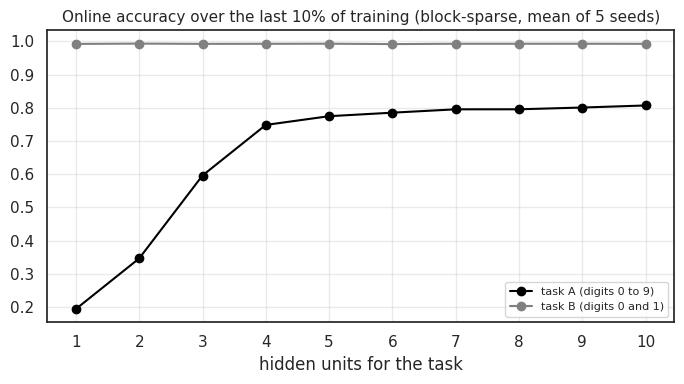

 1 units: task A 19.44%, task B 99.20%
 2 units: task A 34.66%, task B 99.30%
 3 units: task A 59.60%, task B 99.22%
 4 units: task A 74.83%, task B 99.24%
 5 units: task A 77.46%, task B 99.27%
 6 units: task A 78.51%, task B 99.15%
 7 units: task A 79.52%, task B 99.25%
 8 units: task A 79.53%, task B 99.25%
 9 units: task A 80.06%, task B 99.26%
10 units: task A 80.68%, task B 99.23%

N =  4: best split 3/1 (79.40%), even split 2/2 -12.4 points
N =  6: best split 5/1 (88.33%), even split 3/3 -8.9 points
N =  8: best split 7/1 (89.36%), even split 4/4 -2.3 points
N = 10: best split 9/1 (89.63%), even split 5/5 -1.3 points
N = 12: best split 10/2 (89.99%), even split 6/6 -1.2 points


In [7]:
final = slice(-round(N_WINDOWS * FINAL_FRACTION), None)


def final_accuracy(res):
    return res['accuracy'][:, final].mean(1)                 # (seed, task): accuracy over the last FINAL_FRACTION


# Each task's accuracy (mean over seeds) with k hidden units, from the block-sparse network with k units per task.
calibration = np.array([final_accuracy(run(block_sparse(k, k))).mean(0) for k in CALIBRATION_UNITS])    # (k, task)
fig, ax = plt.subplots(figsize=(7, 4))
for task, (label, color) in enumerate([('task A (digits 0 to 9)', 'black'), ('task B (digits 0 and 1)', 'gray')]):
    ax.plot(CALIBRATION_UNITS, calibration[:, task], color=color, marker='o', lw=1.5, label=label)
ax.set_xticks(CALIBRATION_UNITS)
ax.yaxis.set_major_locator(plt.MultipleLocator(0.1))
ax.set_xlabel('hidden units for the task')
ax.set_title(f'Online accuracy over the last 10% of training (block-sparse, mean of {N_SEEDS} seeds)', fontsize=11)
ax.grid(alpha=0.4)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
for k, (a, b) in zip(CALIBRATION_UNITS, calibration):
    print(f'{k:>2} units: task A {a:.2%}, task B {b:.2%}')

# The accuracy over both tasks this predicts for each block-sparse split of N units: task A k, task B N - k.
print()
for n in range(4, 13, 2):
    split = {k: (calibration[k - 1, 0] + calibration[n - k - 1, 1]) / 2 for k in range(max(1, n - 10), min(n, 11))}
    best = max(split, key=split.get)
    print(f'N = {n:>2}: best split {best}/{n - best} ({split[best]:.2%}), even split {n // 2}/{n // 2} '
          f'{100 * (split[n // 2] - split[best]):+.1f} points')

## Results, step 0

- **Task B needs 1 unit; task A needs about 4.** Task B (digits 0 and 1) reaches 99.2% with 1 hidden unit and stays
  there up to 10. Task A rises steeply up to 4 units (19.4%, 34.7%, 59.6% and 74.8% with 1 to 4), then slowly: 77.5%
  with 5, 79.5% with 7 and 80.7% with 10.
- **Predicted splits.** As task B is saturated at 1 unit, the best split of every N gives task B 1 unit (2 at N = 12,
  within noise). The even split's cost then depends only on how far N/2 sits below task A's knee: −12.4 points at
  N = 4 (best split 3/1), −8.9 at N = 6 (5/1), −2.3 at N = 8 (7/1), −1.3 at N = 10 and −1.2 at N = 12.
- **Proposal: N = 6, with step 1 giving task A k = 3, 4 and 5 units** (task B the rest). It is the largest even N that
  meets both targets: the best split gives task A 5 of the 6 units (predicted 88.3%), and the even split 3/3 is
  predicted 8.9 points below it; 4/2 is predicted 1.3 points below the best. N = 8 fails the second target (the even
  split costs only 2.3 points). N = 4 meets both but leaves task A on the steep part of its curve even at the best
  split.
- These predictions use means over 5 seeds without error bars, and combine task A and task B from different networks;
  step 1 measures the splits directly.
- **N = 6 and k = 3, 4 and 5 were confirmed** before steps 1 and 2 ran.

## Step 1: the best split

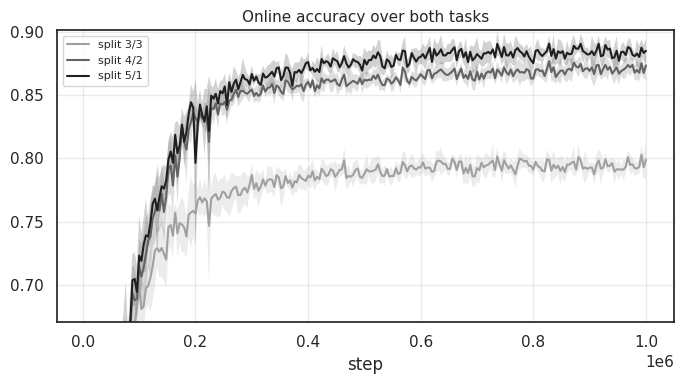

split 3/3   accuracy 79.41% (task A 59.60%, task B 99.22%), units feeding task A 3.0
split 4/2   accuracy 87.05% (task A 74.83%, task B 99.27%), units feeding task A 4.0
split 5/1   accuracy 88.36% (task A 77.46%, task B 99.25%), units feeding task A 5.0
gap, split 4/2 vs split 3/3: +7.63 points (± 0.61)
gap, split 5/1 vs split 3/3: +8.94 points (± 0.67)
H0, the best split gives task A 5 of 6 units: held


In [8]:
window_ends = np.arange(1, N_WINDOWS + 1) * WINDOW
SERIES = {'accuracy': ('Online accuracy over both tasks', lambda res: res['accuracy'].mean(-1)),
          'units': (f'Hidden units feeding task A (task B: the rest of the {N_HIDDEN})',
                    lambda res: res['units'][..., 0])}


def plot_runs(runs, colors, dashed=(), keys=('accuracy', 'units')):
    # The online accuracy over both tasks and the units feeding task A (the `keys` of SERIES) over training for each
    # run in `runs` (mean +- 2 SE over seeds), drawn in `colors[label]`, and dashed for the labels in `dashed`. The
    # accuracy axis starts at the lowest mean accuracy after the first 10% of training.
    fig, axes = plt.subplots(1, len(keys), figsize=(7 * len(keys), 4), squeeze=False)
    for ax, key in zip(axes[0], keys):
        title, series = SERIES[key]
        for label, res in runs.items():
            mean, sem = series(res).mean(0), series(res).std(0) / np.sqrt(N_SEEDS)
            ax.plot(window_ends, mean, color=colors[label], ls='--' if label in dashed else '-', lw=1.5, label=label)
            ax.fill_between(window_ends, mean - 2 * sem, mean + 2 * sem, color=colors[label], alpha=0.2, lw=0)
        ax.set_xlabel('step')
        ax.set_title(title, fontsize=11)
        ax.grid(alpha=0.4)
    curves = [res['accuracy'].mean(-1).mean(0) for res in runs.values()]
    low, high = min(c[N_WINDOWS // 10:].min() for c in curves), max(c.max() for c in curves)
    axes[0, 0].set_ylim(low - 0.05 * (high - low), high + 0.05 * (high - low))
    axes[0, 0].legend(fontsize=8)
    if 'units' in keys:
        axes[0, 1].yaxis.set_major_locator(plt.MultipleLocator(1))
    fig.tight_layout()
    plt.show()


def report(runs, tests):
    # Prints every run's online accuracy over both tasks and on each, and the units feeding task A, over the last
    # FINAL_FRACTION of training; then for each test (name, label, reference, claim) the gap of `label` to `reference`
    # in percentage points (mean and 2 SE over paired seeds), and whether the claim held: more than ACCURACY_TOLERANCE
    # 'below' or 'above' it (no claim: None).
    width = max(map(len, runs))
    for label, res in runs.items():
        a = final_accuracy(res)
        print(f'{label:<{width}}   accuracy {a.mean():.2%} (task A {a[:, 0].mean():.2%}, task B {a[:, 1].mean():.2%}), '
              f'units feeding task A {res["units"][:, final, 0].mean():.1f}')
    for name, label, reference, claim in tests:
        g = final_accuracy(runs[label]).mean(1) - final_accuracy(runs[reference]).mean(1)
        ok = g.mean() < -ACCURACY_TOLERANCE if claim == 'below' else g.mean() > ACCURACY_TOLERANCE
        verdict = '' if claim is None else f': {"held" if ok else "failed"}'
        print(f'{name}, {label} vs {reference}: {100 * g.mean():+.2f} points '
              f'(± {100 * 2 * g.std() / np.sqrt(N_SEEDS):.2f}){verdict}')


split_runs = {f'split {k}/{N_HIDDEN - k}': run(block_sparse(k, N_HIDDEN - k)) for k in SPLITS}
EVEN_LABEL = f'split {N_HIDDEN // 2}/{N_HIDDEN // 2}'
plot_runs(split_runs, dict(zip(split_runs, ('#a0a0a0', '#636363', '#1f1f1f'))), keys=('accuracy',))
report(split_runs, [('gap', label, EVEN_LABEL, None) for label in split_runs if label != EVEN_LABEL])
best_k = max(SPLITS, key=lambda k: final_accuracy(split_runs[f'split {k}/{N_HIDDEN - k}']).mean())
print(f'H0, the best split gives task A {best_k} of {N_HIDDEN} units: {"held" if best_k > N_HIDDEN / 2 else "failed"}')

## Results, step 1

- **H0 held.** The best split gives task A 5 of the 6 units: 88.36% online accuracy, +8.94 points (± 0.67, 2 SE over
  paired seeds) above the even split 3/3 (79.41%). The split 4/2 reaches 87.05% (+7.63 ± 0.61). Step 0 predicted 88.33%
  and 8.9 points.
- **Per task.** Task B is at 99.2–99.3% in every split; task A gets 59.60%, 74.83% and 77.46% with 3, 4 and 5 units.
  Task A's numbers are identical to step 0's: its half of the network starts from the same weights and learns
  separately from task B's.

## Step 2a: shadow weights against the best split

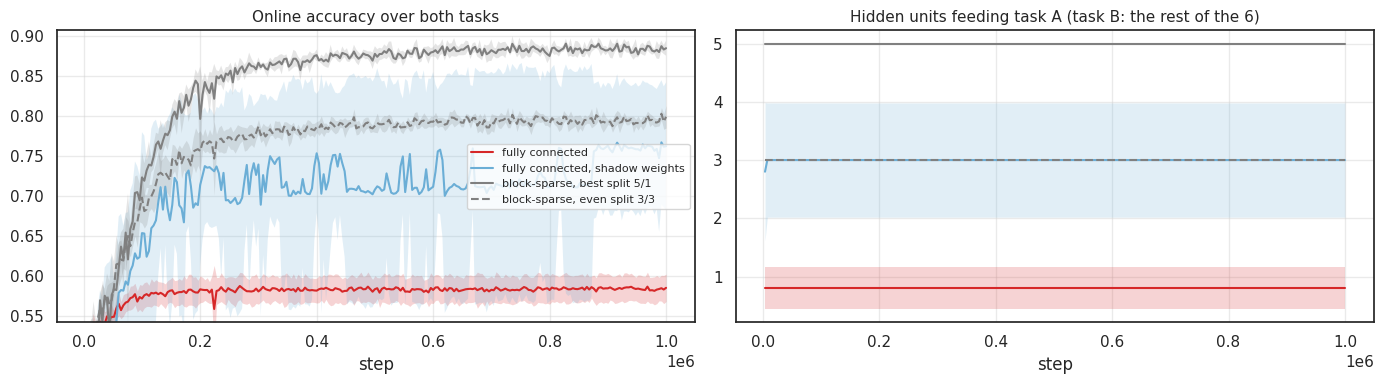

fully connected                   accuracy 58.44% (task A 17.65%, task B 99.23%), units feeding task A 0.8
fully connected, shadow weights   accuracy 76.02% (task A 53.45%, task B 98.59%), units feeding task A 3.0
block-sparse, best split 5/1      accuracy 88.36% (task A 77.46%, task B 99.25%), units feeding task A 5.0
block-sparse, even split 3/3      accuracy 79.41% (task A 59.60%, task B 99.22%), units feeding task A 3.0
H1, fully connected, shadow weights vs block-sparse, best split 5/1: -12.33 points (± 8.17): held
gap, fully connected vs block-sparse, best split 5/1: -29.91 points (± 1.72)
gap, fully connected, shadow weights vs block-sparse, even split 3/3: -3.39 points (± 7.92)
gap, fully connected vs block-sparse, even split 3/3: -20.97 points (± 1.89)


In [9]:
BEST = f'block-sparse, best split {best_k}/{N_HIDDEN - best_k}'
EVEN = f'block-sparse, even split {N_HIDDEN // 2}/{N_HIDDEN // 2}'
references = {BEST: split_runs[f'split {best_k}/{N_HIDDEN - best_k}'], EVEN: split_runs[EVEN_LABEL]}
COLORS = {'fully connected': 'tab:red', 'fully connected, shadow weights': '#6baed6',
          'fully connected, generate and test': '#3182bd',
          'fully connected, shadow weights + generate and test': '#08519c', BEST: 'gray', EVEN: 'gray'}

fc_runs = {'fully connected': run(FULLY_CONNECTED),
           'fully connected, shadow weights': run(FULLY_CONNECTED, shadow=True)}
plot_runs({**fc_runs, **references}, COLORS, dashed=[EVEN])
report({**fc_runs, **references}, [('H1', 'fully connected, shadow weights', BEST, 'below'),
                                   ('gap', 'fully connected', BEST, None),
                                   ('gap', 'fully connected, shadow weights', EVEN, None),
                                   ('gap', 'fully connected', EVEN, None)])

## Results, step 2a

- **H1 held.** Shadow weights reach 76.02%, −12.33 points (± 8.17) below the best split and −3.39 (± 7.92) below the
  even split (task A 53.45%, task B 98.59%).
- **Diagnostic.** Shadow weights keep 3.0 units on task A on average (2 to 4 within the ± 2 SE band), flat from the
  start: their random pairings' share, against 5 in the best split.
- Shadow weights are unstable here: their mean accuracy drops by more than 10 points in single windows late in
  training (plot), and the seeds spread widely (± 8 points on the gaps). Not investigated.
- Fully connected, our method gives nearly every unit to the easy task B: 0.8 units feed task A on average, from the
  first window on. Task A stays near its 1-unit accuracy (17.65%), and the network reaches 58.44%, −29.91 points
  (± 1.72) below the best split.

## Step 2b: adding simple generate and test

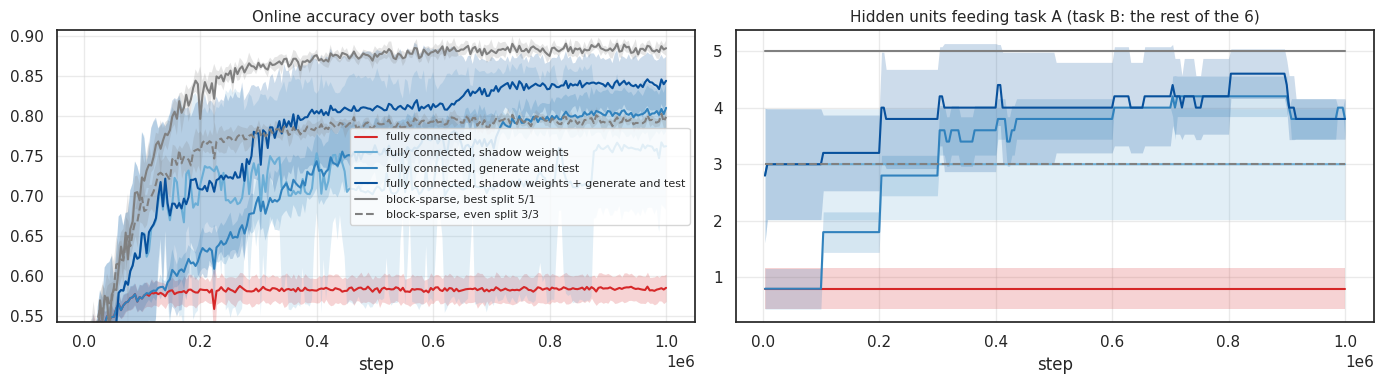

fully connected                                       accuracy 58.44% (task A 17.65%, task B 99.23%), units feeding task A 0.8
fully connected, shadow weights                       accuracy 76.02% (task A 53.45%, task B 98.59%), units feeding task A 3.0
fully connected, generate and test                    accuracy 80.37% (task A 61.48%, task B 99.27%), units feeding task A 3.8
fully connected, shadow weights + generate and test   accuracy 84.01% (task A 68.80%, task B 99.21%), units feeding task A 3.8
block-sparse, best split 5/1                          accuracy 88.36% (task A 77.46%, task B 99.25%), units feeding task A 5.0
block-sparse, even split 3/3                          accuracy 79.41% (task A 59.60%, task B 99.22%), units feeding task A 3.0
H2, fully connected, shadow weights + generate and test vs fully connected, shadow weights: +7.98 points (± 5.06): held
gap, fully connected, generate and test vs fully connected: +21.93 points (± 2.86)
gap, fully connected, generate and 

In [10]:
search_runs = {'fully connected, generate and test': run(FULLY_CONNECTED, search=True),
               'fully connected, shadow weights + generate and test': run(FULLY_CONNECTED, shadow=True, search=True)}
all_runs = {**fc_runs, **search_runs, **references}
plot_runs(all_runs, COLORS, dashed=[EVEN])
report(all_runs, [('H2', 'fully connected, shadow weights + generate and test', 'fully connected, shadow weights',
                   'above'),
                  ('gap', 'fully connected, generate and test', 'fully connected', None),
                  ('gap', 'fully connected, generate and test', BEST, None),
                  ('gap', 'fully connected, shadow weights + generate and test', BEST, None)])

## Results, step 2b

- **H2 held.** Generate and test lifts shadow weights by +7.98 points (± 5.06), to 84.01%, −4.35 (± 3.46) below the
  best split. The units feeding task A rise from 3.0 to 3.8 (last 10%), and the accuracy curve is much steadier.
- Without shadow weights, generate and test moves units from task B to task A: their count rises in steps at the
  first three resets (0.8, 1.8, 2.8, then about 3.6) and ends at 3.8. Accuracy rises +21.93 points (± 2.86), to
  80.37%, still −7.98 (± 2.99) below the best split and still rising at 1M steps.
- Neither run reaches the best split's 5 units for task A. (A reset unit with near-zero output weights counts for
  whichever task they favour, so these counts are noisy by about one unit.)
- So when one task needs most of the units, our method alone gives them to the other, easy task; shadow weights' split
  of about half each falls well short of the best split; and simple generate and test moves units to the task that
  needs them, closing 65–73% of each gap within 1M steps.